# Missing Fewer Inhibitors at the Same Precision Target

**Goal: retain at least 90% training CV precision while increasing recall.** The previous model's threshold already maximized recall subject to that constraint on its scores. This experiment compares models using that objective instead of overall AP.

The bounded search covers five candidates: Logistic Regression, Random Forest, Extra Trees, and variants of the last two considering 20% of features per split. Morgan fingerprints, scaffold partitions, and the random seed stay the same.

Model and threshold selection use training OOF scores. Only the selected model is compared with the previous model on the already inspected test set. This is not new independent validation; improvement is not guaranteed. Select **Run All**.

**Outcome:** the training-selected Extra Trees candidate did not improve test recall (FN 564 → 565). It remains an experiment in `herg_candidate.joblib`; the app retained the previous model at that stage. The subsequent representation experiment is in notebook 06.

## 1. Previous and selected models

The previous precision model is saved as `models/herg_precision_baseline.joblib`. We verify dataset identity, matching test rows, and OOF/test separation.

In [1]:
from pathlib import Path
from hashlib import sha256
import sys
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from sklearn.metrics import (precision_recall_curve, precision_score, recall_score,
    f1_score, confusion_matrix, ConfusionMatrixDisplay)
from rdkit import Chem
from rdkit.Chem import Draw

ROOT = Path.cwd().resolve()
if not (ROOT / "src").is_dir() and (ROOT.parent / "src").is_dir():
    ROOT = ROOT.parent
if not (ROOT / "src").is_dir():
    raise RuntimeError("Open from the project root or notebooks directory.")
sys.path.insert(0, str(ROOT))
from src.modeling import select_model_at_precision
baseline_path = ROOT / "models/herg_precision_baseline.joblib"
active_path = ROOT / "models/herg_candidate.joblib"
if not baseline_path.is_file() or not active_path.is_file():
    raise FileNotFoundError("Both the saved baseline and selected experiment artifact are required; see README.")
old = joblib.load(baseline_path)  # Only load your own trusted artifacts.
a = joblib.load(active_path)
if a.get("selection_metric") != "recall_at_precision" or not a.get("candidate_thresholds"):
    raise ValueError("Run the policy-aware search with --model-path models/herg_candidate.joblib first; see README.")
assert a["dataset_sha256"] == old["dataset_sha256"] == sha256((ROOT / "data/raw/herg_karim.csv").read_bytes()).hexdigest()
assert a["threshold_selection"]["min_precision"] == old["threshold_selection"]["min_precision"]
target = a["threshold_selection"]["min_precision"]
oof = a["oof_predictions"]
assert oof.row_index.is_unique
assert set(oof.row_index) == set(a["train_indices"])
assert set(oof.row_index).isdisjoint(a["test_predictions"].row_index)
assert set(oof.scaffold).isdisjoint(a["test_predictions"].scaffold)
assert oof.groupby("scaffold").fold.nunique().eq(1).all()
selected_name, candidates = select_model_at_precision(a["cv_metrics"], a["candidate_oof_scores"], oof.label, target)
assert selected_name == a["model_name"]
assert candidates == a["candidate_thresholds"]
assert candidates[selected_name] == a["threshold_selection"]
assert set(old["test_predictions"].row_index) == set(a["test_predictions"].row_index)
assert set(old["train_indices"]) == set(a["train_indices"])
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.18})
display(pd.DataFrame([
    {"Run": "Previous", "Model": old["model_name"], "Threshold": old["decision_threshold"],
     "OOF precision": old["threshold_selection"]["precision"], "OOF recall": old["threshold_selection"]["recall"]},
    {"Run": "Selected", "Model": a["model_name"], "Threshold": a["decision_threshold"],
     "OOF precision": a["threshold_selection"]["precision"], "OOF recall": a["threshold_selection"]["recall"]},
]).set_index("Run"))

,Model,Threshold,OOF precision,OOF recall
Run,,,,
Previous,Random forest,0.672021,0.900596,0.534226
Selected,Extra trees,0.697718,0.900873,0.537574


## 2. Model selection using training OOF data

All candidates receive the same 90% precision target. Each gets its maximum-recall feasible threshold; the model with the highest resulting recall wins. Ties prefer mean CV AP, then model name. Candidates with infeasible targets are excluded.

These OOF metrics were used for selection and are not independent estimates. Candidate test results do not appear in this table.

,Feasible,OOF precision,OOF recall,Threshold,Mean CV AP,Selected
Model,,,,,,
Logistic regression,True,0.9004,0.2742,0.9593,0.8118,False
Random forest,True,0.9006,0.5342,0.6720,0.8757,False
Extra trees,True,0.9009,0.5376,0.6977,0.8722,True
Random forest (20% features),True,0.9019,0.5318,0.7042,0.8677,False
Extra trees (20% features),True,0.9007,0.5143,0.7700,0.8637,False


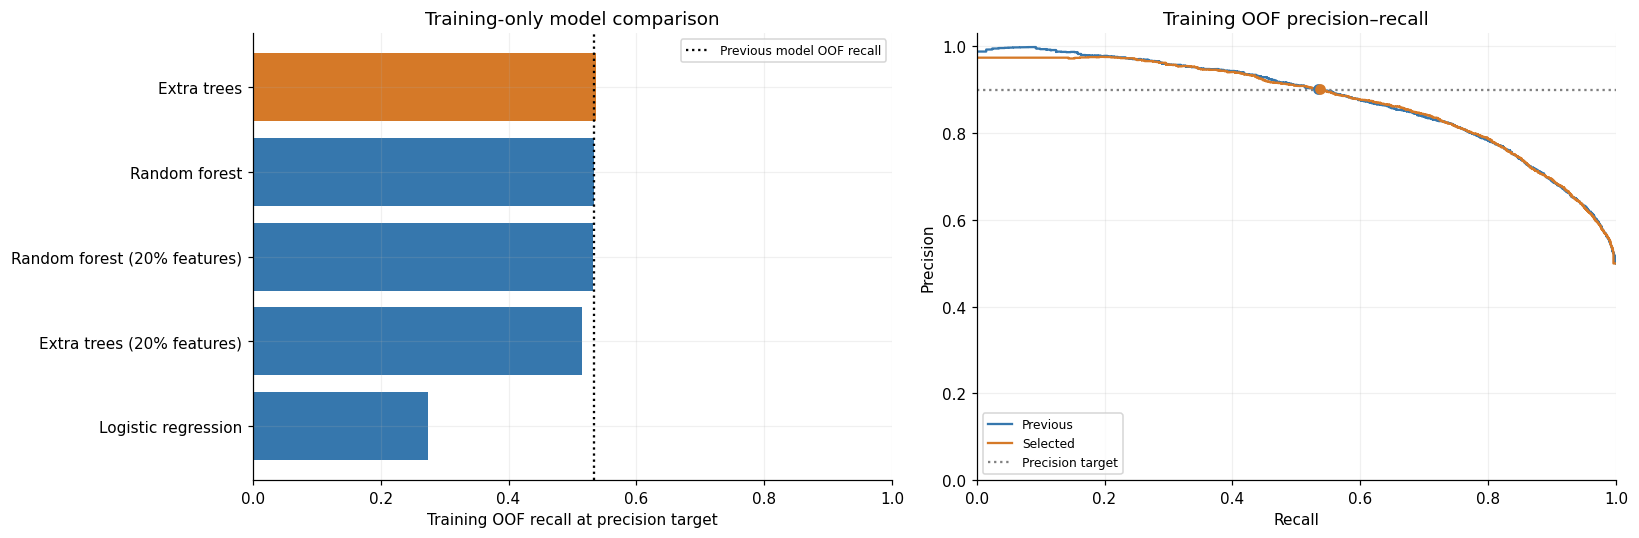

In [2]:
rows = []
for name, policy in candidates.items():
    rows.append({"Model": name, "Feasible": "threshold" in policy,
        "OOF precision": policy.get("precision", np.nan), "OOF recall": policy.get("recall", np.nan),
        "Threshold": policy.get("threshold", np.nan), "Mean CV AP": a["cv_metrics"][name]["auprc"]["mean"],
        "Selected": name == selected_name})
comparison_oof = pd.DataFrame(rows).set_index("Model")
display(comparison_oof.round(4))
valid = comparison_oof[comparison_oof.Feasible].sort_values("OOF recall")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(valid.index, valid["OOF recall"], color=["#d57928" if name == selected_name else "#3677ad" for name in valid.index])
axes[0].axvline(old["threshold_selection"]["recall"], color="black", linestyle=":", label="Previous model OOF recall")
axes[0].set(xlabel="Training OOF recall at precision target", xlim=(0, 1), title="Training-only model comparison")
axes[0].legend(fontsize=8)
for artifact, label, color in [(old, "Previous", "#3677ad"), (a, "Selected", "#d57928")]:
    scores = artifact["oof_predictions"]
    precision, recall, _ = precision_recall_curve(scores.label, scores.score)
    axes[1].step(recall, precision, where="post", label=label, color=color)
    policy = artifact["threshold_selection"]
    axes[1].scatter(policy["recall"], policy["precision"], color=color, zorder=4)
axes[1].axhline(target, color="gray", linestyle=":", label="Precision target")
axes[1].set(xlabel="Recall", ylabel="Precision", xlim=(0, 1), ylim=(0, 1.03), title="Training OOF precision–recall")
axes[1].legend(fontsize=8, loc="lower left")
fig.tight_layout()
plt.show()

## 3. Test comparison for the selected model only

Both models use the same test compounds and thresholds fixed using training OOF data. The 90% precision target may not hold on test data; we do not readjust thresholds using test results.

Inspect precision, recall, and FN together. Fewer false negatives alone are insufficient if the precision loss conflicts with the objective.

,Precision,Recall,F1,TN,FP,FN,TP
Run,,,,,,,
Previous precision model,0.9142,0.5797,0.7095,1265,73,564,778
Selected precision model,0.9152,0.5790,0.7093,1266,72,565,777


,Selected minus previous
Precision,0.0010
Recall,-0.0007
F1,-0.0003
TN,1.0000
FP,-1.0000
FN,1.0000
TP,-1.0000


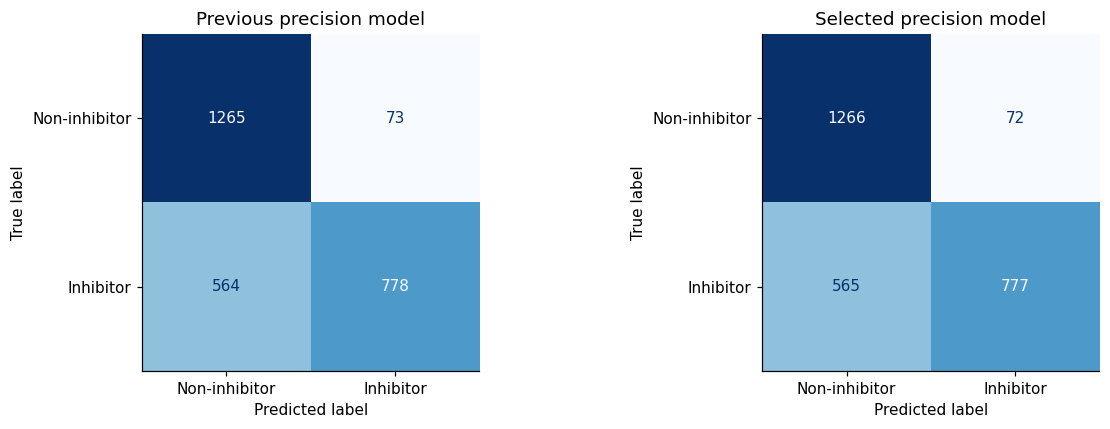

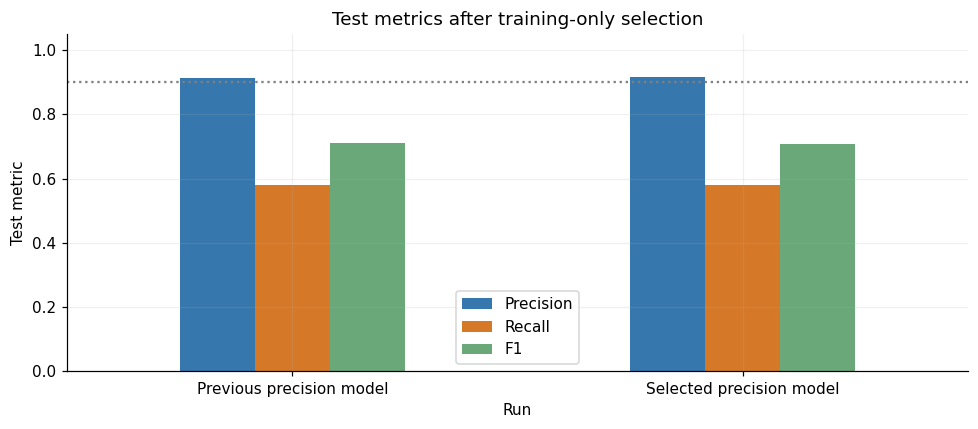

In [3]:
test_rows = []
for name, artifact in [("Previous precision model", old), ("Selected precision model", a)]:
    test = artifact["test_predictions"]
    prediction = test.threshold_prediction
    np.testing.assert_array_equal(prediction, test.score >= artifact["decision_threshold"])
    tn, fp, fn, tp = confusion_matrix(test.label, prediction, labels=[0, 1]).ravel()
    test_rows.append({"Run": name,
        "Precision": precision_score(test.label, prediction, zero_division=0),
        "Recall": recall_score(test.label, prediction, zero_division=0),
        "F1": f1_score(test.label, prediction, zero_division=0),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp})
comparison_test = pd.DataFrame(test_rows).set_index("Run")
display(comparison_test.round(4))
display((comparison_test.iloc[1] - comparison_test.iloc[0]).rename("Selected minus previous").to_frame().round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, title, artifact in zip(axes, ["Previous precision model", "Selected precision model"], [old, a]):
    test = artifact["test_predictions"]
    ConfusionMatrixDisplay.from_predictions(test.label, test.threshold_prediction, labels=[0, 1],
        display_labels=["Non-inhibitor", "Inhibitor"], cmap="Blues", ax=ax, colorbar=False, values_format="d")
    ax.set_title(title)
    ax.grid(False)
fig.tight_layout()
plt.show()
comparison_test[["Precision", "Recall", "F1"]].plot.bar(figsize=(9, 4), rot=0,
    color=["#3677ad", "#d57928", "#6aa879"])
plt.axhline(target, color="gray", linestyle=":")
plt.ylim(0, 1.05)
plt.ylabel("Test metric")
plt.xlabel("Run")
plt.title("Test metrics after training-only selection")
plt.tight_layout()
plt.show()

## 4. Which inhibitors were additionally detected?

We join test results by row identifier and separately count previously missed inhibitors now detected, as well as the reverse change. Images show up to six newly detected inhibitors in dataset row order, not selected for extreme scores.

,Count
Previously missed inhibitors now detected,37
Previously detected inhibitors now missed,38
Net additional inhibitors detected,-1


,row_index,label,previous_prediction,threshold_prediction,score,smiles
95,430,1,0,1,0.740000,CC(=O)c1cccc(-c2cccc(-n3cc(C(=O)Nc4nccc(Cl)c4C...
110,482,1,0,1,1.000000,CN1CCN=C1c1ccc(C(=O)N2CCN(S(=O)(=O)c3cc4ccc(Cl...
216,986,1,0,1,0.740000,COCC(O)CN(Cc1ccc(F)cc1)C(=O)CC1CCN(Cc2ccc(-c3c...
244,1149,1,0,1,0.803333,O=C(NCCCN1CCOCC1)Nc1ccc(S(=O)(=O)Nc2ccccc2C(=O...
360,1694,1,0,1,0.776667,Cc1cccnc1CN1CCC2(CC1)C(=O)N(c1ccc(-c3ccc(-c4cc...
381,1811,1,0,1,0.713333,COC(=O)C1(CNC(=O)c2cc(OC)cc(OC)c2)CCN(Cc2cccc(...


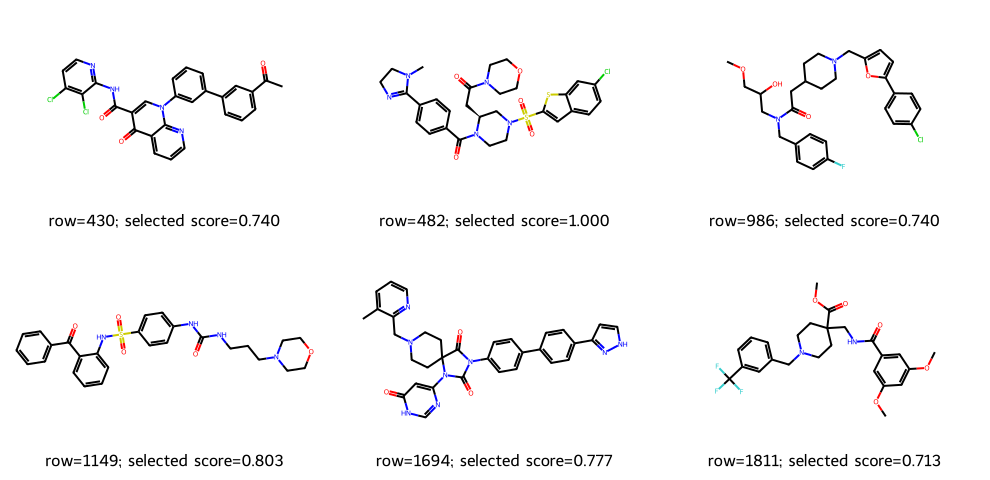

In [4]:
joined = old["test_predictions"][["row_index", "label", "threshold_prediction"]].rename(
    columns={"threshold_prediction": "previous_prediction"}).merge(
    a["test_predictions"][["row_index", "label", "smiles", "score", "threshold_prediction"]],
    on="row_index", how="inner", suffixes=("_old", ""), validate="one_to_one")
assert joined.label_old.eq(joined.label).all()
recovered = joined[(joined.label == 1) & (joined.previous_prediction == 0) & (joined.threshold_prediction == 1)].sort_values("row_index")
new_misses = joined[(joined.label == 1) & (joined.previous_prediction == 1) & (joined.threshold_prediction == 0)]
display(pd.Series({"Previously missed inhibitors now detected": len(recovered),
    "Previously detected inhibitors now missed": len(new_misses),
    "Net additional inhibitors detected": len(recovered) - len(new_misses)}, name="Count").to_frame())
display(recovered[["row_index", "label", "previous_prediction", "threshold_prediction", "score", "smiles"]].head(6))
examples = recovered.head(6)
if not examples.empty:
    display(Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in examples.smiles], molsPerRow=3,
        subImgSize=(330, 240), legends=[f"row={row.row_index}; selected score={row.score:.3f}"
                                     for row in examples.itertuples()]))
else:
    display(Markdown("No newly detected inhibitors in this comparison."))

## 5. Limitations

- The precision constraint applies to training OOF data and is not a guarantee for new compounds.
- This test set has already been inspected. Repeated analysis and model changes require a new independent dataset for confirmation.
- Good aggregate metrics do not establish safety for an individual molecule.
- The app model is subsequently refitted on all rows, which can shift scores.
- Any larger search or alternative features should again use training data only, with the selection rule fixed in advance.

## Result of this experiment

The selected Extra Trees candidate achieved slightly higher training OOF recall at the 90% precision target: **53.42% → 53.76%**. This improvement did not carry over to the test set: precision **91.42% → 91.52%**, recall **57.97% → 57.90%**, FN **564 → 565**, and FP **73 → 72**.

This is effectively similar performance and does **not** meet the goal of fewer missed inhibitors. The app model was not replaced. We did not lower the precision target or search test thresholds to obtain a favorable result. Confirming a meaningful improvement requires stronger training-only experiments and independent validation; this run does not establish one.